In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plt.rcParams["font.family"] = "Arial"

from statsmodels.stats.multitest import multipletests
from scipy import stats

from additives_microbiota.constants import ADDITIVE_VARS, MIXTURES
from additives_microbiota.plotting import process_string, process_string_pretty_vars
from additives_microbiota.group_statistics import create_quartiles

## Load Metadata

In [2]:
meta = pd.read_csv("../../data/metadata_files/meta_zscores.csv", index_col=0)

bmi_order = ["Underweight", "Normal", "Overweight", "Obese"]
meta["bmi_cat"] = pd.Categorical(meta["bmi_cat"], categories=bmi_order, ordered=True)

meta["HEI_Quartile"] = meta["HEI_Quartile"].astype("category")
meta["HEI_Quartile"] = meta["HEI_Quartile"].cat.set_categories(
    ["Q1", "Q2", "Q3", "Q4"], ordered=True
)

meta["age_group_2"] = meta["age_group_2"].astype("category")
meta["age_group_2"] = meta["age_group_2"].cat.set_categories(
    ["<35", "35-50", ">50"], ordered=True
)

## Merging with average additive consumption
# meta = meta.merge(k_across_days_avg.reset_index(), on="subject_key")
# meta = meta.merge(food_category_consumption_by_user, on="subject_key")

# Plotting 

In [3]:
def _log1p_safe(s):
    x = s.astype(float)
    if (x < 0).any():
        raise ValueError(
            "Additive exposure contains negative values; log1p requires values >= 0."
        )
    return np.log1p(x)


def _mannwhitney_effect_and_p(x1, x2):
    """
    Returns:
      u, p, rbc, delta_median, n1, n2
    Notes:
      rbc is rank-biserial correlation, positive means x1 tends to be higher than x2.
    """
    x1 = pd.Series(x1).dropna().astype(float)
    x2 = pd.Series(x2).dropna().astype(float)

    n1, n2 = int(x1.shape[0]), int(x2.shape[0])
    if n1 < 3 or n2 < 3:
        return np.nan, np.nan, np.nan, np.nan, n1, n2

    u, p = stats.mannwhitneyu(x1, x2, alternative="two-sided")
    rbc = (2.0 * u) / (n1 * n2) - 1.0
    delta_median = float(np.nanmedian(x1) - np.nanmedian(x2))
    return float(u), float(p), float(rbc), delta_median, n1, n2


def compute_extremes_trend_grid(
    df,
    additive_vars,
    cont_quartile_vars,
    cat_contrasts,
    q_low="Q1",
    q_high="Q4",
    transform_additives="log1p",
    fdr_alpha=0.05,
    min_n_per_group=10,
):
    """
    Build a long results table for a heatmap panel of descriptive trends.

    Args:
      df: single DataFrame containing both metadata and additive vars (one row per participant).
      additive_vars: list of additive exposure columns.
      cont_quartile_vars: list of continuous metadata columns for Q1 vs Q4 comparison.
      cat_contrasts: dict like {"language": ["latin","german"], "urbanity": ["urban","rural"]}.
                     Each list must be length 2 and values must exist in df[col].
      q_low/q_high: quartile labels created by create_quartiles.
      transform_additives: "log1p" or None. If "log1p", tests are run on log1p(additive).
      fdr_alpha: threshold for significance markers using BH FDR.
      min_n_per_group: minimum sample size per group to run the cell test.

    Returns:
      res: long DataFrame with one row per (predictor, additive) cell
    """
    dfw = df.copy()

    # Transform additive outcomes once
    if transform_additives == "log1p":
        for a in additive_vars:
            dfw[a + "_t"] = _log1p_safe(dfw[a])
        additive_cols = [a + "_t" for a in additive_vars]
    elif transform_additives is None:
        additive_cols = list(additive_vars)
    else:
        raise ValueError("transform_additives must be 'log1p' or None")

    # Create quartiles for continuous vars
    for x in cont_quartile_vars:
        if x + "_quartile" not in dfw.columns:
            dfw = create_quartiles(dfw, x, ncut=4)

    rows = []

    # Continuous predictors: Q4 vs Q1
    for x in cont_quartile_vars:
        qcol = x + "_quartile"
        for a_base, a in zip(additive_vars, additive_cols):
            sub = dfw[[qcol, a]].dropna()
            g_hi = sub.loc[sub[qcol] == q_high, a]
            g_lo = sub.loc[sub[qcol] == q_low, a]

            u, p, rbc, dmed, n1, n2 = _mannwhitney_effect_and_p(g_hi, g_lo)

            # enforce min_n_per_group
            if (n1 < min_n_per_group) or (n2 < min_n_per_group):
                p = np.nan
                rbc = np.nan
                dmed = np.nan

            rows.append(
                {
                    "predictor": x,
                    "predictor_type": "continuous_extremes",
                    "contrast": f"{q_high} vs {q_low}",
                    "additive_group": a_base,
                    "p_value": p,
                    "effect_rbc": rbc,  # good for coloring, comparable
                    "delta_median": dmed,  # optional alternative for coloring
                    "n_group1": n1,  # group1 is high quartile
                    "n_group2": n2,  # group2 is low quartile
                }
            )

    # Categorical predictors: specified pairwise contrasts
    for x, lvls in (cat_contrasts or {}).items():
        if (not isinstance(lvls, (list, tuple))) or len(lvls) != 2:
            raise ValueError(f"cat_contrasts[{x}] must be a list of exactly 2 levels")

        lvl1, lvl2 = lvls[0], lvls[1]
        for a_base, a in zip(additive_vars, additive_cols):
            sub = dfw[[x, a]].dropna()
            sub = sub[sub[x].isin([lvl1, lvl2])]
            g1 = sub.loc[sub[x] == lvl1, a]
            g2 = sub.loc[sub[x] == lvl2, a]

            u, p, rbc, dmed, n1, n2 = _mannwhitney_effect_and_p(g1, g2)

            if (n1 < min_n_per_group) or (n2 < min_n_per_group):
                p = np.nan
                rbc = np.nan
                dmed = np.nan

            rows.append(
                {
                    "predictor": x,
                    "predictor_type": "categorical_pair",
                    "contrast": f"{lvl1} vs {lvl2}",
                    "additive_group": a_base,
                    "p_value": p,
                    "effect_rbc": rbc,  # positive means lvl1 tends higher than lvl2
                    "delta_median": dmed,
                    "n_group1": n1,
                    "n_group2": n2,
                }
            )

    res = pd.DataFrame(rows)

    # FDR across all tested cells (excluding NaNs)
    res["q_value"] = np.nan
    ok = res["p_value"].notna()
    if ok.any():
        res.loc[ok, "q_value"] = multipletests(
            res.loc[ok, "p_value"].values, method="fdr_bh"
        )[1]
    res["star"] = ""

    res.loc[res["q_value"] < 0.001, "star"] = "***"
    res.loc[(res["q_value"] >= 0.001) & (res["q_value"] < 0.01), "star"] = "**"
    res.loc[(res["q_value"] >= 0.01) & (res["q_value"] < 0.05), "star"] = "*"

    res["predictor_label"] = res["predictor"]
    res.loc[res["predictor_type"] == "continuous_extremes", "predictor_label"] = (
        res.loc[res["predictor_type"] == "continuous_extremes", "predictor"].astype(str)
        + f" ({q_high} vs {q_low})"
    )
    res.loc[res["predictor_type"] == "categorical_pair", "predictor_label"] = (
        res.loc[res["predictor_type"] == "categorical_pair", "predictor"].astype(str)
        + " ("
        + res.loc[res["predictor_type"] == "categorical_pair", "contrast"].astype(str)
        + ")"
    )

    return res


def make_heatmap_mats_from_extremes(res, value_col="effect_rbc"):
    # preserve original predictor_label order as they appear in res
    ordered_labels = res["predictor_label"].drop_duplicates().tolist()

    values = res.pivot(
        index="predictor_label",
        columns="additive_group",
        values=value_col,
    ).reindex(ordered_labels)

    stars = res.pivot(
        index="predictor_label",
        columns="additive_group",
        values="star",
    ).reindex(ordered_labels)

    return values, stars


def _pretty_with_suffix(s):
    if isinstance(s, str) and " (" in s:
        base, suffix = s.split(" (", 1)
        return process_string_pretty_vars(base) + " (" + suffix
    return process_string_pretty_vars(s)


def plot_trend_heatmap(
    values,
    stars=None,
    ax=None,
    title=None,
    annotate=True,
    cbar_label="effect",
    cmap="RdBu_r",
    figsize=(10, 8),
):
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    A = values.to_numpy()

    vmax = np.nanmax(np.abs(A))
    if not np.isfinite(vmax) or vmax == 0:
        vmax = 1.0
    vmin = -vmax

    im = ax.imshow(A, aspect="auto", vmin=vmin, vmax=vmax, cmap=cmap)

    ax.set_yticks(range(values.shape[0]))
    ax.set_yticklabels([_pretty_with_suffix(s) for s in values.index.tolist()])

    ax.set_xticks(range(values.shape[1]))
    ax.set_xticklabels(
        [process_string_pretty_vars(s) for s in values.columns.tolist()],
        rotation=45,
        ha="right",
        rotation_mode="anchor",
    )

    if title:
        ax.set_title(title)

    cbar = plt.colorbar(im, ax=ax, label=cbar_label, shrink=0.6)

    if annotate and stars is not None:
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                s = stars.iloc[i, j]
                if isinstance(s, str) and s:
                    ax.text(
                        j,
                        i,
                        s,
                        ha="center",
                        va="center",
                        fontsize=10,
                        fontweight="bold",
                    )

    plt.tight_layout()
    return fig, ax

In [4]:
CONT_Q_VARS = [
    # list of continuous metadata columns for quartiles
    "carb_eaten",
    "protein_eaten",
    "fat_eaten",
    "fiber_eaten",
    "sugar_eaten",
    "alcohol_eaten",
    # "fatty_acids_polyunsaturated_eaten",  # Not Significant
    # "fatty_acids_monounsaturated_eaten",  # Not Significant
    # "fatty_acids_saturated_eaten",
    "energy_kcal_eaten",
    "HEI",
    "daily_HEI",
    "vegetables_fg_eaten",
    "fruits_fg_eaten",
    "fast_food_fg_eaten",
    "oils_nuts_fg_eaten",
    "meat_fg_eaten",
    # "coffee_fg_eaten",  # Not Significant
    # "dairy_fg_eaten",  # Not Significant
    "vegan_fg_eaten",
    "bmi",
]

CAT_CONTRASTS = {
    "age_group_2": ["<35", ">50"],
    "gender": ["male", "female"],
    # "antibiotics_treatment": ["True", "False"], # Not Significant
    # "urbanity": ["urban", "rural"],  # Not Significant
    "language": ["latin", "german"],
    "smoking": ["smoker", "non-smoker"],
    "swiss_citizen": ["swiss", "foreign"],
}

res_trends = compute_extremes_trend_grid(
    df=meta,
    additive_vars=[i for i in ADDITIVE_VARS if i not in ["other_additives"]]
    + ["total_additive_intake"],
    cont_quartile_vars=CONT_Q_VARS,
    cat_contrasts=CAT_CONTRASTS,
    transform_additives="log1p",
    fdr_alpha=0.05,
    min_n_per_group=10,
)

vals, stars = make_heatmap_mats_from_extremes(res_trends, value_col="effect_rbc")

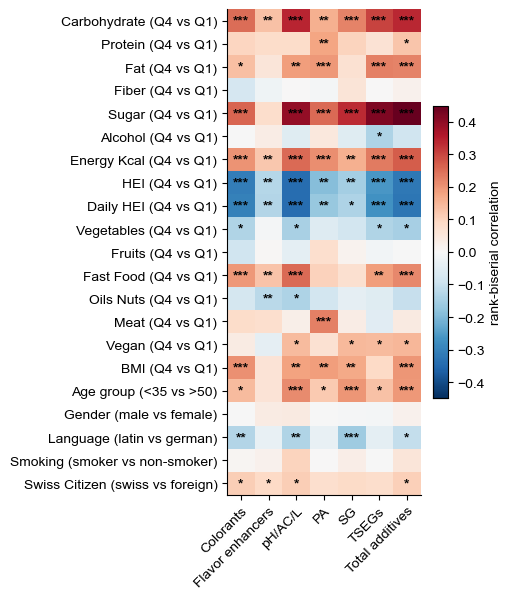

In [5]:
fig, ax = plot_trend_heatmap(
    values=vals,
    stars=stars,
    title=None,
    annotate=True,
    cbar_label="rank-biserial correlation",
    figsize=(5, 6.1),
)

sns.despine()

In [6]:
vals

additive_group,colorants,flavor_enhancers,ph_regulators_anti_caking_leavening_agents,preservatives_antioxidants,sweeteners_glazing_agents,thickeners_stabilizers_emulsifiers_gelling_agents,total_additive_intake
predictor_label,,,,,,,
carb_eaten (Q4 vs Q1),0.249664,0.132139,0.340651,0.157904,0.220740,0.302456,0.337796
protein_eaten (Q4 vs Q1),0.094682,0.083328,0.081782,0.176263,0.100981,0.065960,0.123891
fat_eaten (Q4 vs Q1),0.133835,0.054505,0.186576,0.193816,0.067018,0.227257,0.220505
fiber_eaten (Q4 vs Q1),-0.075887,-0.020290,0.001898,-0.009003,0.058049,0.000235,0.019635
sugar_eaten (Q4 vs Q1),0.260128,0.079985,0.394366,0.254921,0.335679,0.418604,0.447931
alcohol_eaten (Q4 vs Q1),-0.003208,0.034702,-0.054723,0.046023,-0.052876,-0.136808,-0.090130
energy_kcal_eaten (Q4 vs Q1),0.202298,0.119004,0.253040,0.209755,0.157854,0.232313,0.270324
HEI (Q4 vs Q1),-0.310804,-0.128863,-0.342079,-0.189079,-0.152815,-0.260179,-0.319706
daily_HEI (Q4 vs Q1),-0.301498,-0.132307,-0.341743,-0.170435,-0.137665,-0.270509,-0.322309


In [7]:
stars

additive_group,colorants,flavor_enhancers,ph_regulators_anti_caking_leavening_agents,preservatives_antioxidants,sweeteners_glazing_agents,thickeners_stabilizers_emulsifiers_gelling_agents,total_additive_intake
predictor_label,,,,,,,
carb_eaten (Q4 vs Q1),***,**,***,**,***,***,***
protein_eaten (Q4 vs Q1),,,,**,,,*
fat_eaten (Q4 vs Q1),*,,**,***,,***,***
fiber_eaten (Q4 vs Q1),,,,,,,
sugar_eaten (Q4 vs Q1),***,,***,***,***,***,***
alcohol_eaten (Q4 vs Q1),,,,,,*,
energy_kcal_eaten (Q4 vs Q1),***,**,***,***,**,***,***
HEI (Q4 vs Q1),***,**,***,**,**,***,***
daily_HEI (Q4 vs Q1),***,**,***,**,*,***,***


## version 2: Adding feature groups to the y-axis labels

In [8]:
def _strip_suffix(label):
    # label may be like "carb_eaten (Q4 vs Q1)" or "gender (male vs female)"
    if isinstance(label, str) and " (" in label:
        return label.split(" (", 1)[0]
    return label


def _group_for_predictor(predictor, feature_groups):
    for gname, members in feature_groups.items():
        if predictor in members:
            return gname
    return None


def _compute_group_spans(values_index, feature_groups):
    # returns list of (start_row, end_row_exclusive, group_name)
    groups = []
    prev_g = None
    start = 0

    base_preds = [_strip_suffix(s) for s in values_index.tolist()]
    gseq = [_group_for_predictor(p, feature_groups) for p in base_preds]

    for i, g in enumerate(gseq):
        if i == 0:
            prev_g, start = g, 0
            continue
        if g != prev_g:
            if prev_g is not None:
                groups.append((start, i, prev_g))
            start = i
            prev_g = g

    if prev_g is not None:
        groups.append((start, len(gseq), prev_g))

    return groups

In [9]:
def plot_trend_heatmap_v2(
    values,
    stars=None,
    ax=None,
    title=None,
    annotate=True,
    cbar_label="effect",
    cmap="RdBu_r",
    figsize=(10, 8),
    feature_groups=None,
    group_linecolors=None,
    group_linewidth=8,
    group_x=-0.55,
):
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    A = values.to_numpy()

    vmax = np.nanmax(np.abs(A))
    if not np.isfinite(vmax) or vmax == 0:
        vmax = 1.0
    vmin = -vmax

    im = ax.imshow(A, aspect="auto", vmin=vmin, vmax=vmax, cmap=cmap)

    if feature_groups is not None:
        spans = _compute_group_spans(values.index, feature_groups)

        for i0, i1, gname in spans:
            ax.vlines(
                group_x,
                i0 - 0.5,
                i1 - 0.5,
                colors=GROUP_COLORS.get(gname, "0.3"),
                linewidth=group_linewidth,
                clip_on=False,
                zorder=4,
            )

        ax.set_xlim(-1.0, values.shape[1] - 0.5)

    ax.set_yticks(range(values.shape[0]))
    ax.set_yticklabels([_pretty_with_suffix(s) for s in values.index.tolist()])

    ax.set_xticks(range(values.shape[1]))
    ax.set_xticklabels(
        [process_string_pretty_vars(s) for s in values.columns.tolist()],
        rotation=45,
        ha="right",
        rotation_mode="anchor",
    )

    if title:
        ax.set_title(title)

    cbar = plt.colorbar(
        im,
        ax=ax,
        label=cbar_label,
        shrink=0.85,
        orientation="horizontal",
        location="top",
        pad=0.03,
    )
    cbar.outline.set_visible(False)

    if annotate and stars is not None:
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                s = stars.iloc[i, j]
                if isinstance(s, str) and s:
                    ax.text(
                        j,
                        i,
                        s,
                        ha="center",
                        va="center",
                        fontsize=10,
                        fontweight="bold",
                        zorder=3,
                    )

    handles = [
        Line2D([0], [0], color=c, lw=4, label=k.replace("_", " ").title())
        for k, c in GROUP_COLORS.items()
    ]

    legend = ax.legend(
        handles=handles,
        frameon=False,
        title="Variable Type",
        loc="upper left",
        bbox_to_anchor=(-0.6, -0.04),
        handlelength=0.8,
        handletextpad=0.6,
        borderaxespad=0.0,
        fontsize=9,
    )
    # Make legend text italics
    for text in legend.get_texts():
        text.set_fontstyle("italic")

    return fig, ax

In [10]:
FEATURE_GROUPS = {
    "nutrients": {
        "carb_eaten",
        "protein_eaten",
        "fat_eaten",
        "fiber_eaten",
        "sugar_eaten",
        "alcohol_eaten",
        # "fatty_acids_polyunsaturated_eaten",
        # "fatty_acids_monounsaturated_eaten",
        # "fatty_acids_saturated_eaten",
        "energy_kcal_eaten",
    },
    "diet_indices": {"HEI", "daily_HEI"},
    "food_groups": {
        "vegetables_fg_eaten",
        "fruits_fg_eaten",
        "fast_food_fg_eaten",
        "oils_nuts_fg_eaten",
        "meat_fg_eaten",
        "vegan_fg_eaten",
    },
    "demographics": {
        "bmi",
        # categorical predictors
        "age_group_2",
        "gender",
        "language",
        "smoking",
        "swiss_citizen",
    },
}

GROUP_COLORS = {
    "nutrients": "#55A868",
    "diet_indices": "#4C72B0",
    "food_groups": "darkgoldenrod",
    "demographics": "indigo",
}

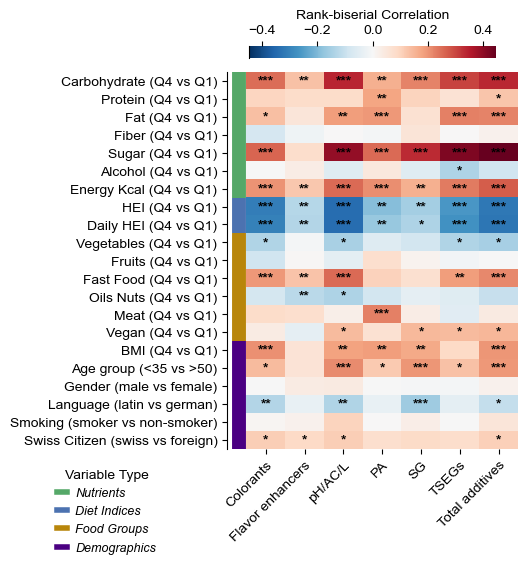

In [11]:
fig, ax = plot_trend_heatmap_v2(
    values=vals,
    stars=stars,
    title=None,
    annotate=True,
    cbar_label="Rank-biserial Correlation",
    figsize=(6, 6),
    feature_groups=FEATURE_GROUPS,
    group_linewidth=10,
    group_x=-0.7,
    # cmap="RdGy",
    cmap="RdBu_r",
)

plt.tight_layout()
sns.despine(top=True, bottom=True, left=False, right=True)

plt.savefig(
    "../figures/additive_descriptive/additive_intake_extremes_analysis.png", dpi=300
)

## Making plot for using the entire data 
##### (not just extremes)

In [16]:
def compute_continuous_trend_grid(
    df,
    additive_vars,
    cont_vars,
    cat_contrasts,
    transform_additives="log1p",
    corr_method="spearman",
    fdr_method="fdr_bh",
    min_n=50,
):
    """
    Continuous alternative to the Q4 vs Q1 extremes grid.
    - Continuous predictors: Spearman or Pearson correlation between predictor and additive exposure.
    - Categorical predictors: keeps your existing MWU rank-biserial for the specified pairwise contrasts.

    Returns a long DataFrame analogous to compute_extremes_trend_grid, but with
    predictor_type = 'continuous_corr' for continuous predictors.
    """
    dfw = df.copy()

    # Transform additive outcomes once
    if transform_additives == "log1p":
        for a in additive_vars:
            dfw[a + "_t"] = _log1p_safe(dfw[a])
        additive_cols = [a + "_t" for a in additive_vars]
    elif transform_additives is None:
        additive_cols = list(additive_vars)
    else:
        raise ValueError("transform_additives must be 'log1p' or None")

    rows = []

    # Continuous predictors: correlation on full data
    for x in cont_vars:
        for a_base, a in zip(additive_vars, additive_cols):
            sub = dfw[[x, a]].dropna()
            n = int(sub.shape[0])
            if n < min_n:
                r = np.nan
                p = np.nan
            else:
                if corr_method == "spearman":
                    r, p = stats.spearmanr(sub[x].astype(float), sub[a].astype(float))
                elif corr_method == "pearson":
                    r, p = stats.pearsonr(sub[x].astype(float), sub[a].astype(float))
                else:
                    raise ValueError("corr_method must be 'spearman' or 'pearson'")

                r = float(r)
                p = float(p)

            rows.append(
                {
                    "predictor": x,
                    "predictor_type": "continuous_corr",
                    "contrast": corr_method,
                    "additive_group": a_base,
                    "p_value": p,
                    "effect": r,  # correlation coefficient
                    "n": n,
                }
            )

    # Categorical predictors: specified pairwise contrasts (unchanged from your extremes approach)
    for x, lvls in (cat_contrasts or {}).items():
        if (not isinstance(lvls, (list, tuple))) or len(lvls) != 2:
            raise ValueError(f"cat_contrasts[{x}] must be a list of exactly 2 levels")

        lvl1, lvl2 = lvls[0], lvls[1]
        for a_base, a in zip(additive_vars, additive_cols):
            sub = dfw[[x, a]].dropna()
            sub = sub[sub[x].isin([lvl1, lvl2])]
            g1 = sub.loc[sub[x] == lvl1, a]
            g2 = sub.loc[sub[x] == lvl2, a]

            u, p, rbc, dmed, n1, n2 = _mannwhitney_effect_and_p(g1, g2)

            rows.append(
                {
                    "predictor": x,
                    "predictor_type": "categorical_pair",
                    "contrast": f"{lvl1} vs {lvl2}",
                    "additive_group": a_base,
                    "p_value": p,
                    "effect": rbc,  # keep comparable sign convention for categorical
                    "delta_median": dmed,
                    "n_group1": n1,
                    "n_group2": n2,
                }
            )

    res = pd.DataFrame(rows)

    # FDR across all tested cells (excluding NaNs)
    res["q_value"] = np.nan
    ok = res["p_value"].notna()
    if ok.any():
        res.loc[ok, "q_value"] = multipletests(
            res.loc[ok, "p_value"].values, method=fdr_method
        )[1]

    res["star"] = ""
    res.loc[res["q_value"] < 0.001, "star"] = "***"
    res.loc[(res["q_value"] >= 0.001) & (res["q_value"] < 0.01), "star"] = "**"
    res.loc[(res["q_value"] >= 0.01) & (res["q_value"] < 0.05), "star"] = "*"

    # Labels
    res["predictor_label"] = res["predictor"]
    res.loc[res["predictor_type"] == "continuous_corr", "predictor_label"] = (
        res.loc[res["predictor_type"] == "continuous_corr", "predictor"].astype(str)
        # + f" ({corr_method})"
    )
    res.loc[res["predictor_type"] == "categorical_pair", "predictor_label"] = (
        res.loc[res["predictor_type"] == "categorical_pair", "predictor"].astype(str)
        + " ("
        + res.loc[res["predictor_type"] == "categorical_pair", "contrast"].astype(str)
        + ")"
    )

    return res


def make_heatmap_mats_from_continuous(res, value_col="effect"):
    ordered_labels = res["predictor_label"].drop_duplicates().tolist()

    values = res.pivot(
        index="predictor_label",
        columns="additive_group",
        values=value_col,
    ).reindex(ordered_labels)

    stars = res.pivot(
        index="predictor_label",
        columns="additive_group",
        values="star",
    ).reindex(ordered_labels)

    return values, stars

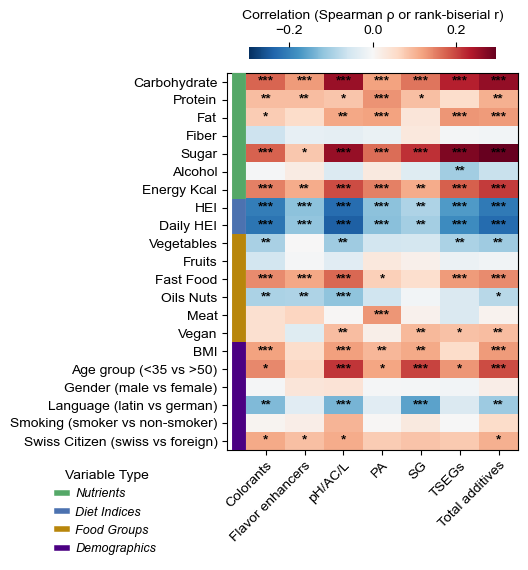

In [18]:
# Use your existing CONT_Q_VARS and CAT_CONTRASTS, but now treat CONT_Q_VARS as continuous variables
res_trends_cont = compute_continuous_trend_grid(
    df=meta,
    additive_vars=[i for i in ADDITIVE_VARS if i not in ["other_additives"]]
    + ["total_additive_intake"],
    cont_vars=CONT_Q_VARS,
    cat_contrasts=CAT_CONTRASTS,
    transform_additives="log1p",
    corr_method="spearman",
    fdr_method="fdr_bh",
    min_n=50,
)

vals_cont, stars_cont = make_heatmap_mats_from_continuous(
    res_trends_cont, value_col="effect"
)

fig, ax = plot_trend_heatmap_v2(
    values=vals_cont,
    stars=stars_cont,
    title=None,
    annotate=True,
    cbar_label="Correlation (Spearman ρ or rank-biserial r)",
    figsize=(6, 6),
    feature_groups=FEATURE_GROUPS,
    group_linewidth=10,
    group_x=-0.7,
    cmap="RdBu_r",
)

plt.tight_layout()

plt.savefig(
    "../figures/additive_descriptive/additive_intake_continuous_associations_heatmap.png",
    dpi=300,
)